In [1]:
import anndata as ad
import os
spatial_dir = '/work/magroup/skrieger/Syndri/data/xenium_noise_experiment'


st_data = ad.read_h5ad(os.path.join(spatial_dir,"GSM9509174_breast_breast_B1_B1_3_rctd_annotated_dropout_25pct.h5ad"))
st_data

AnnData object with n_obs × n_vars = 108069 × 277
    obs: 'cell_id', 'cells_parquet_matched', 'x_centroid', 'y_centroid', 'transcript_counts', 'control_probe_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'deprecated_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'sample_id', 'gsm_accession', 'source_h5', 'source_cells_parquet', 'xenium_n_umi', 'rctd_input_pass', 'rctd_spot_class', 'rctd_first_type', 'rctd_second_type', 'rctd_first_class', 'rctd_second_class', 'rctd_first_assignment_class_only', 'rctd_second_assignment_class_only', 'rctd_min_score', 'rctd_singlet_score', 'rctd_secondary_removed_for_singlet', 'rctd_first_weight', 'rctd_second_weight', 'batch', 'harmony_cell_type', 'split_trial_0_first_type', 'split_trial_0_n_cell_types', 'split_trial_0_primary_cell_type', 'split_trial_0_purification_status', 'split_trial_0_w1_primary', 'split_trial_1_first_type', 'split_trial_1_n_cell_types', 'split_trial_1_primary_cell_type', 'split_trial_1_purificat

In [ ]:
# import scanpy as sc
# import numpy as np
# st_data = st_data[st_data.obs['source_h5']=='GSM9509174_breast_breast_B1_B1_3_cell_feature_matrix.h5']
# idx = np.random.choice(st_data.n_obs, size=int(st_data.n_obs * 0.1), replace=False)
# st_data = st_data[idx]

In [94]:
import sys
from argparse import Namespace

import anndata as ad

sys.path.insert(0, "/home/jwinchel/Syndri/eval")
from metrics_eval import (
    cleaned_counts_for_removed_fraction_maybe_grouped,
    sanitize_numeric_matrix,
)

# adata = ad.read_h5ad("/path/to/file.h5ad")

args = Namespace(
    cleaning_mode="probability_scale",
    probability_transform="power",
    probability_power=2.0,
    probability_sigmoid_midpoint=0.5,
    probability_sigmoid_steepness=10.0,
    tcell_probability_removal_scale=1.0,
    cell_type_specific_removal=True,
)

X = sanitize_numeric_matrix(st_data.layers['trial_0'].copy())
probs = st_data.layers["admix_probs_trial_0"]
labels = st_data.obs["harmony_cell_type"]

X_cleaned, threshold, achieved, removal_scale, group_thresholds, group_scales, group_achieved = (
    cleaned_counts_for_removed_fraction_maybe_grouped(
        X,
        probs,
        target_removed_fraction=0.2,
        args=args,
        labels=labels,
    )
)

st_data.layers["syndri_cleaned_20pct"] = X_cleaned



KeyError: 'trial_0'

TypeError: 'Axes' object is not iterable

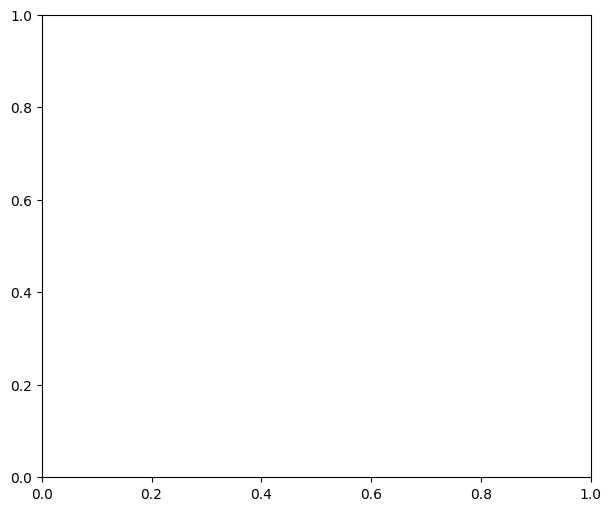

In [95]:
import numpy as np
import matplotlib.pyplot as plt
import scanpy as sc
import scipy.sparse as sp

# ------------------------------------------------------------------
# Configuration
# ------------------------------------------------------------------
layer_map = {
    "Raw counts": None,  # adata.X
    # "Transcript dropout: trial 0": "trial_0",
    # "SPLIT purified: trial 0": "split_purified_counts_trial_0",
    # "Syndri purified: trial 0": "syndri_cleaned_20pct",
}

color_by = "harmony_cell_type"  # replace with your desired adata.obs column
n_top_genes = 277
n_pcs = 30
n_neighbors = 15
random_state = 42


# ------------------------------------------------------------------
# Validation
# ------------------------------------------------------------------
missing_layers = [
    layer
    for layer in layer_map.values()
    if layer is not None and layer not in st_data.layers
]

if missing_layers:
    raise KeyError(f"Missing layers: {missing_layers}")

# if color_by not in st_data.obs:
#     raise KeyError(f"{color_by!r} is not present in adata.obs")


# ------------------------------------------------------------------
# Helper for extracting one raw-count matrix
# ------------------------------------------------------------------
def get_matrix(adata, layer):
    """Return an independent copy of .X or the specified layer."""
    X = adata.X if layer is None else adata.layers[layer]
    return X.copy()


# ------------------------------------------------------------------
# Select one common set of HVGs using the original raw counts
# ------------------------------------------------------------------
hvg_adata = st_data.copy()
hvg_adata.X = get_matrix(st_data, layer=None)

sc.pp.normalize_total(hvg_adata, target_sum=1e4)
sc.pp.log1p(hvg_adata)

# sc.pp.highly_variable_genes(
#     hvg_adata,
#     n_top_genes=n_top_genes,
#     flavor="seurat",
# )

# hvg_names = hvg_adata.var_names[hvg_adata.var["highly_variable"]].copy()

# print(f"Using {len(hvg_names):,} common highly variable genes")


# ------------------------------------------------------------------
# Compute a separate UMAP for each count matrix
# ------------------------------------------------------------------
umap_adatas = {}

for title, layer in layer_map.items():
    current = st_data.copy()
    current.X = get_matrix(st_data, layer)

    # Use exactly the same genes in all three analyses
    # current = current[:, hvg_names].copy()

    # Standard single-cell preprocessing
    sc.pp.normalize_total(current, target_sum=1e4)
    sc.pp.log1p(current)

    sc.pp.pca(
        current,
        n_comps=min(n_pcs, current.n_vars - 1),
        random_state=random_state,
    )

    sc.pp.neighbors(
        current,
        n_neighbors=n_neighbors,
        n_pcs=min(n_pcs, current.obsm["X_pca"].shape[1]),
        random_state=random_state,
    )

    sc.tl.umap(
        current,
        random_state=random_state,
    )

    umap_adatas[title] = current


# ------------------------------------------------------------------
# Plot the three UMAPs side by side
# ------------------------------------------------------------------
fig, axes = plt.subplots(
    1,
    len(umap_adatas),
    figsize=(6 * len(umap_adatas), 5),
    constrained_layout=True,
)

for ax, (title, current) in zip(axes, umap_adatas.items()):
    sc.pl.umap(
        current,
        # color=color_by,
        title=title,
        ax=ax,
        show=False,
        frameon=False,
        legend_loc=None,
        size=8,
    )

# Add one shared legend using the final axis
handles, labels = axes[-1].get_legend_handles_labels()

if handles:
    fig.legend(
        handles,
        labels,
        # title=color_by,
        loc="center left",
        bbox_to_anchor=(1.01, 0.5),
        frameon=False,
    )

plt.show()

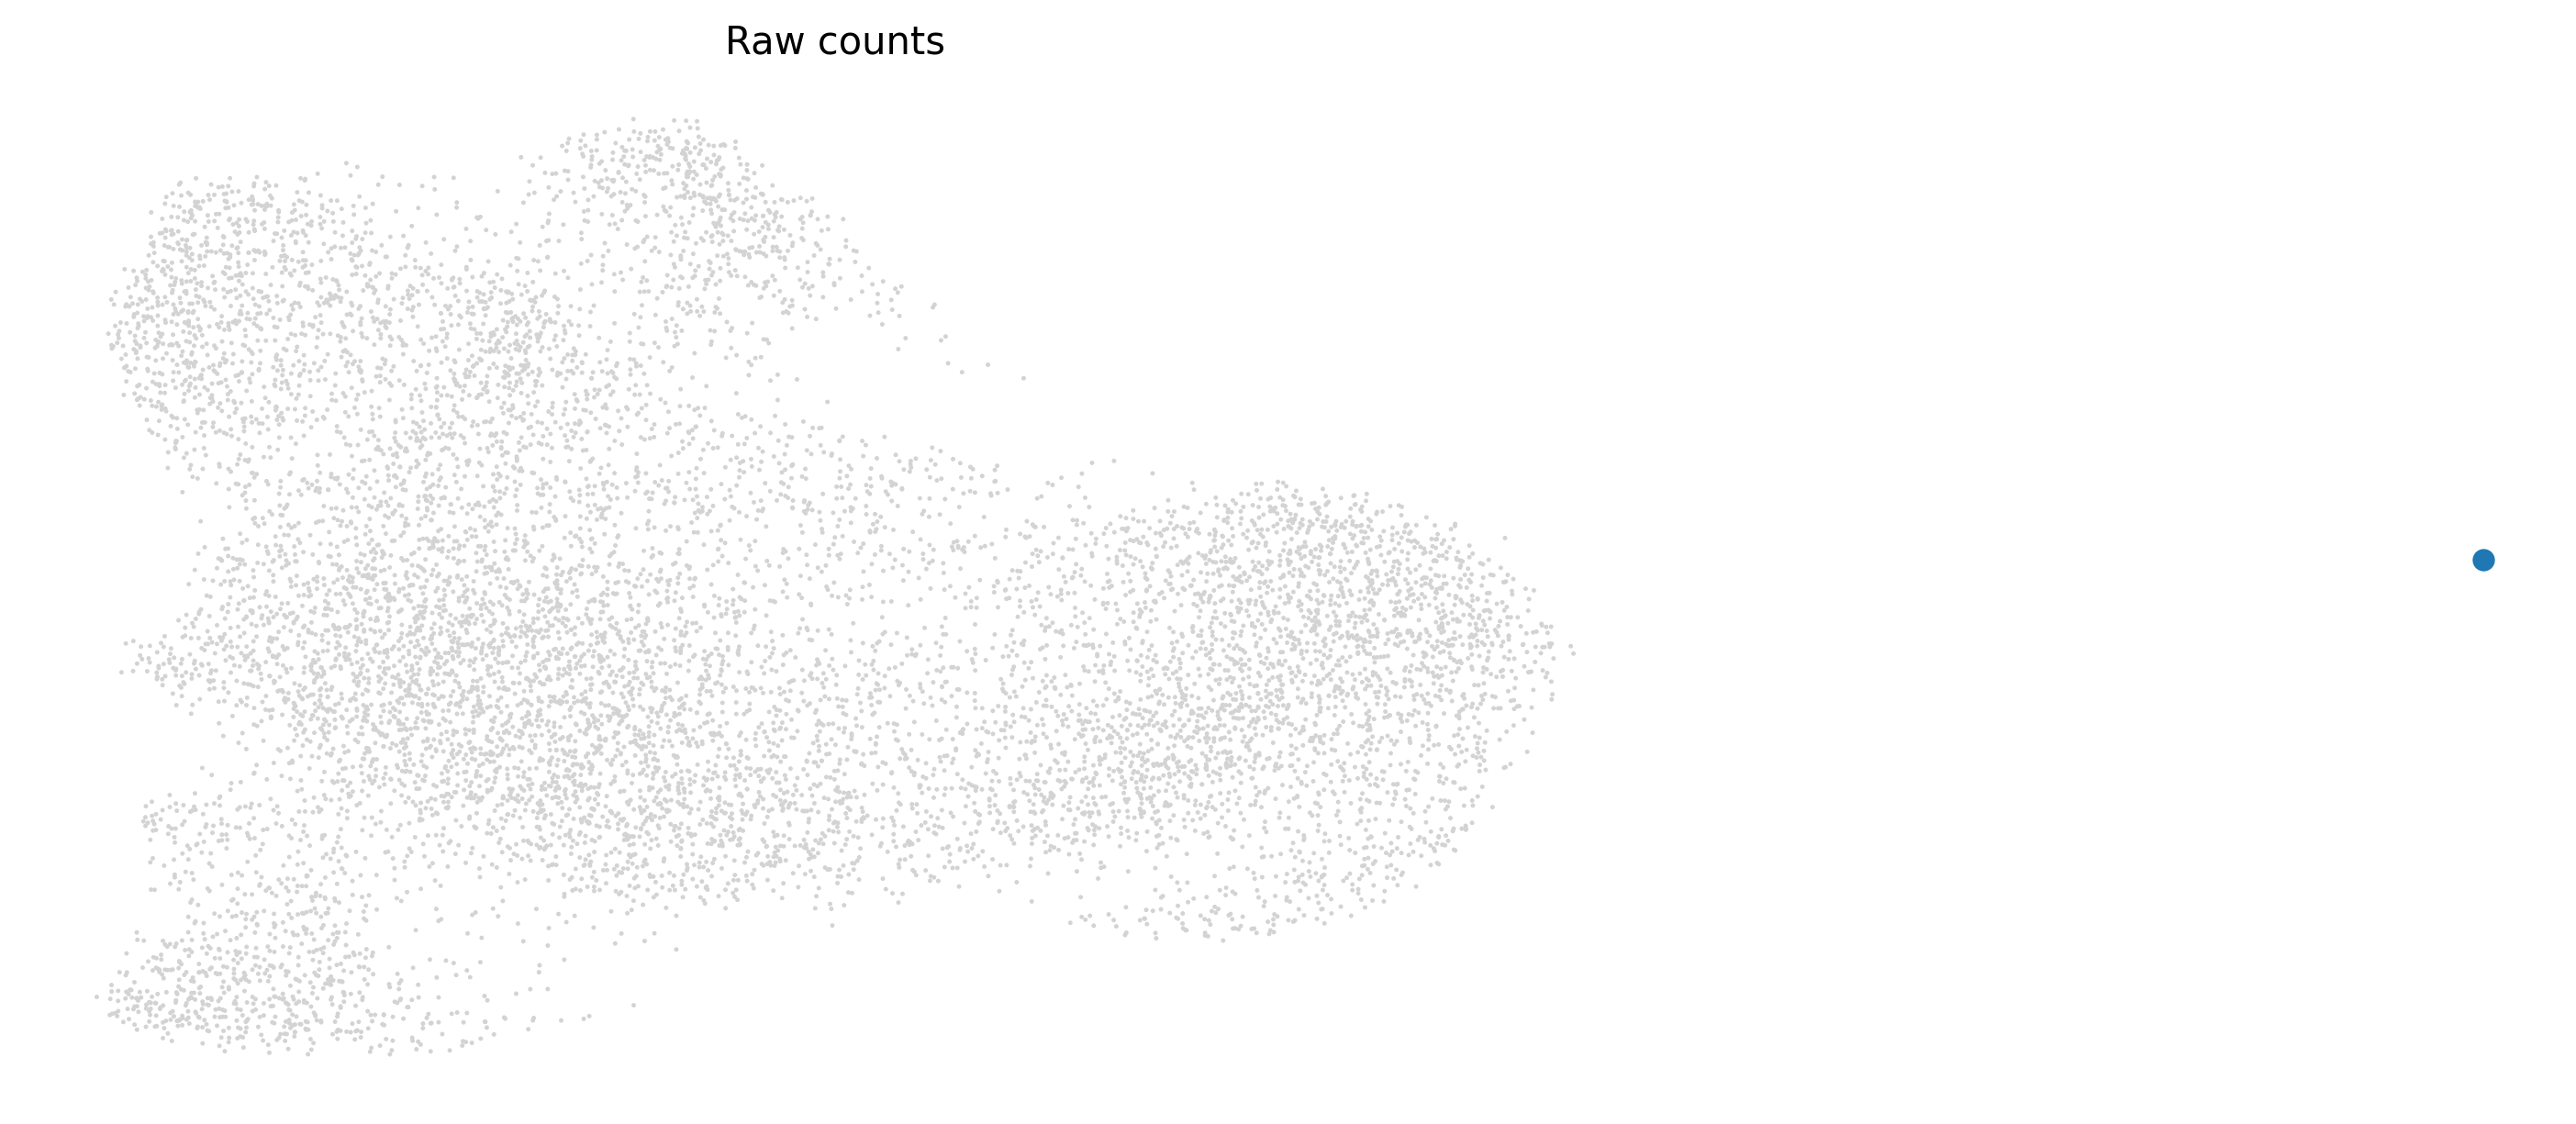

In [96]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import scanpy as sc

items = list(umap_adatas.items())

# Collect all categories across the datasets
# categories = sorted({
#     str(value)
#     for _, current in items
#     for value in current.obs[color_by].dropna().unique()
# })

# Use one fixed color mapping for every panel
scanpy_colors = sc.pl.palettes.default_20

# if len(categories) > len(scanpy_colors):
#     raise ValueError(
#         f"{len(categories)} categories, but only "
#         f"{len(scanpy_colors)} palette colors are available."
#     )

# palette = {
#     category: scanpy_colors[i]
#     for i, category in enumerate(categories)
# }

# Make sure every AnnData uses the same categorical ordering
# for _, current in items:
#     current.obs[color_by] = pd.Categorical(
#         current.obs[color_by].astype(str),
#         categories=categories,
#         ordered=True,
#     )

fig, axes = plt.subplots(
    1,
    len(items),
    figsize=(6 * len(items) + 3, 5),
    squeeze=False,
    dpi=250
)

axes = axes.ravel()

for ax, (title, current) in zip(axes, items):
    sc.pl.umap(
        current,
        # color=color_by,
        # palette=palette,
        title=title,
        ax=ax,
        show=False,
        frameon=False,
        legend_loc=None,
        size=8,
    )

# Explicit proxy artists for a shared legend
legend_handles = [
    Line2D(
        [0],
        [0],
        marker="o",
        linestyle="",
        # markerfacecolor=palette[category],
        markeredgecolor="none",
        markersize=7,
        # label=category,
    )
#     for category in categories
]

fig.legend(
    handles=legend_handles,
    # labels=categories,
    # title=color_by,
    loc="center right",
    bbox_to_anchor=(1.25, 0.5),
    frameon=False,
    ncol=1,
)

# Reserve space on the right for the legend
fig.tight_layout(rect=[0, 0, 0.82, 1])

plt.show()

In [30]:
color_by

'harmony_cell_type'

In [3]:
from umap import UMAP
import seaborn as sns
import matplotlib.pyplot as plt
import anndata as ad
import pandas as pd
import numpy as np

pcs = st_data.obsm['X_pca_harmony']

pcs = (pcs-np.mean(pcs,axis=0))/np.std(pcs,axis=0)

coords = UMAP(n_components=2).fit_transform(pcs)

st_data.obsm['X_pca_harmony_UMAP'] = coords

<Axes: >

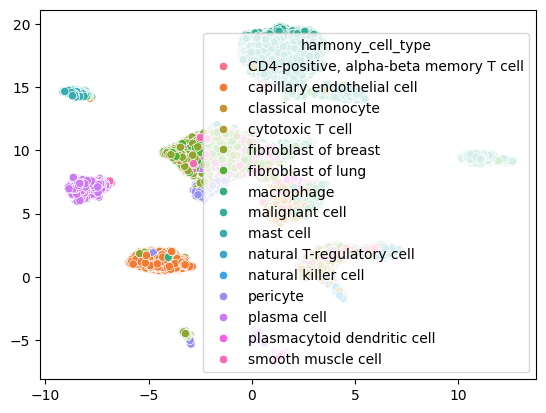

In [5]:
sns.scatterplot(x=st_data.obsm['X_pca_harmony_UMAP'][:,0],y=st_data.obsm['X_pca_harmony_UMAP'][:,1],hue=st_data.obs['harmony_cell_type'])